In [1]:
!pip install pandas numpy matplotlib seaborn


[notice] A new release of pip is available: 23.2.1 -> 26.2.1
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import pandas as pd
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns 
import warnings
warnings.filterwarnings('ignore')

sns.set_style('whitegrid')
plt.rcParams['figure.dpi'] =  100 
np.random.seed(1234)

In [3]:
df = pd.read_csv('../data/heart_failure_clinical_records_dataset.csv')

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 299 entries, 0 to 298
Data columns (total 13 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   age                       299 non-null    float64
 1   anaemia                   299 non-null    int64  
 2   creatinine_phosphokinase  299 non-null    int64  
 3   diabetes                  299 non-null    int64  
 4   ejection_fraction         299 non-null    int64  
 5   high_blood_pressure       299 non-null    int64  
 6   platelets                 299 non-null    float64
 7   serum_creatinine          299 non-null    float64
 8   serum_sodium              299 non-null    int64  
 9   sex                       299 non-null    int64  
 10  smoking                   299 non-null    int64  
 11  time                      299 non-null    int64  
 12  DEATH_EVENT               299 non-null    int64  
dtypes: float64(3), int64(10)
memory usage: 30.5 KB


In [5]:
df.shape

(299, 13)

Inference: Dataset has 299 samples, 13 features. All features are numeric (3 float64, 10 int64). No missing values.

In [6]:
df.head()

,age,anaemia,creatinine_phosphokinase,diabetes,ejection_fraction,high_blood_pressure,platelets,serum_creatinine,serum_sodium,sex,smoking,time,DEATH_EVENT
0,75.0,0,582,0,20,1,265000.00,1.9,130,1,0,4,1
1,55.0,0,7861,0,38,0,263358.03,1.1,136,1,0,6,1
2,65.0,0,146,0,20,0,162000.00,1.3,129,1,1,7,1
3,50.0,1,111,0,20,0,210000.00,1.9,137,1,0,7,1
4,65.0,1,160,1,20,0,327000.00,2.7,116,0,0,8,1


In [7]:
df.isnull().sum()

age                         0
anaemia                     0
creatinine_phosphokinase    0
diabetes                    0
ejection_fraction           0
high_blood_pressure         0
platelets                   0
serum_creatinine            0
serum_sodium                0
sex                         0
smoking                     0
time                        0
DEATH_EVENT                 0
dtype: int64

In [8]:
df.duplicated().sum()

np.int64(0)

In [9]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
age,299.0,60.833893,11.894809,40.0,51.0,60.0,70.0,95.0
anaemia,299.0,0.431438,0.496107,0.0,0.0,0.0,1.0,1.0
creatinine_phosphokinase,299.0,581.839465,970.287881,23.0,116.5,250.0,582.0,7861.0
diabetes,299.0,0.418060,0.494067,0.0,0.0,0.0,1.0,1.0
ejection_fraction,299.0,38.083612,11.834841,14.0,30.0,38.0,45.0,80.0
high_blood_pressure,299.0,0.351171,0.478136,0.0,0.0,0.0,1.0,1.0
platelets,299.0,263358.029264,97804.236869,25100.0,212500.0,262000.0,303500.0,850000.0
serum_creatinine,299.0,1.393880,1.034510,0.5,0.9,1.1,1.4,9.4
serum_sodium,299.0,136.625418,4.412477,113.0,134.0,137.0,140.0,148.0
sex,299.0,0.648829,0.478136,0.0,0.0,1.0,1.0,1.0


### Target Distribution

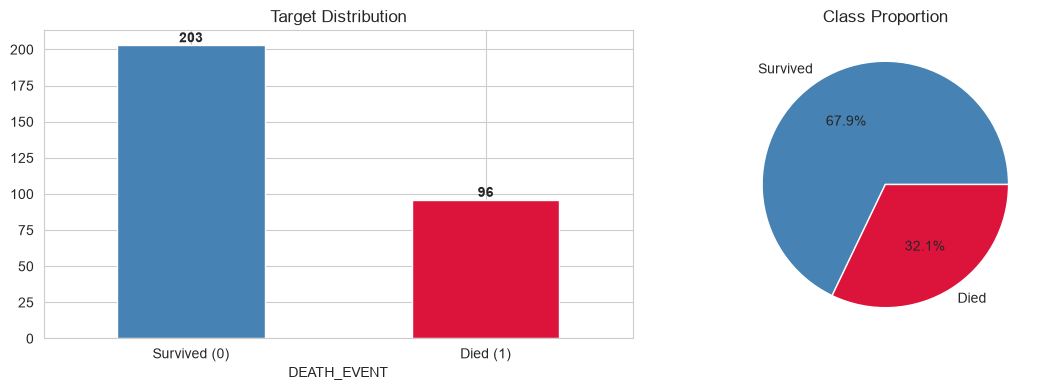

In [10]:
fig, axes = plt.subplots(1, 2, figsize = (12, 4))
df['DEATH_EVENT'].value_counts().plot(kind = "bar", ax = axes[0], color = ["steelblue", "crimson"])
axes[0].set_title("Target Distribution")
axes[0].set_xticklabels(["Survived (0)", "Died (1)"], rotation = 0)
for i, v in enumerate(df['DEATH_EVENT'].value_counts()):
    axes[0].text(i, v+2, str(v), ha='center', fontweight='bold')

df['DEATH_EVENT'].value_counts(normalize=True).plot(kind='pie', ax=axes[1],
    labels=['Survived', 'Died'], autopct='%1.1f%%', colors=['steelblue','crimson'])
axes[1].set_ylabel('')
axes[1].set_title('Class Proportion')
plt.tight_layout()
plt.show()

In [11]:
print(f"Death rate: {df['DEATH_EVENT'].mean():.2%}")
print(f"Baseline accuracy (always survived): {1 - df['DEATH_EVENT'].mean():.2%}")

Death rate: 32.11%
Baseline accuracy (always survived): 67.89%


Inferences:
- Class imbalance: 67.89% Survived (203) vs 32.1% Died (96).
- Baseline accuracy (always predict majority) = 67.89% - any model must beat this.
- Imbalance is moderate, not severe - accuracy alon must be misleading, use F1/ROC-AUC

### Feature Distribution

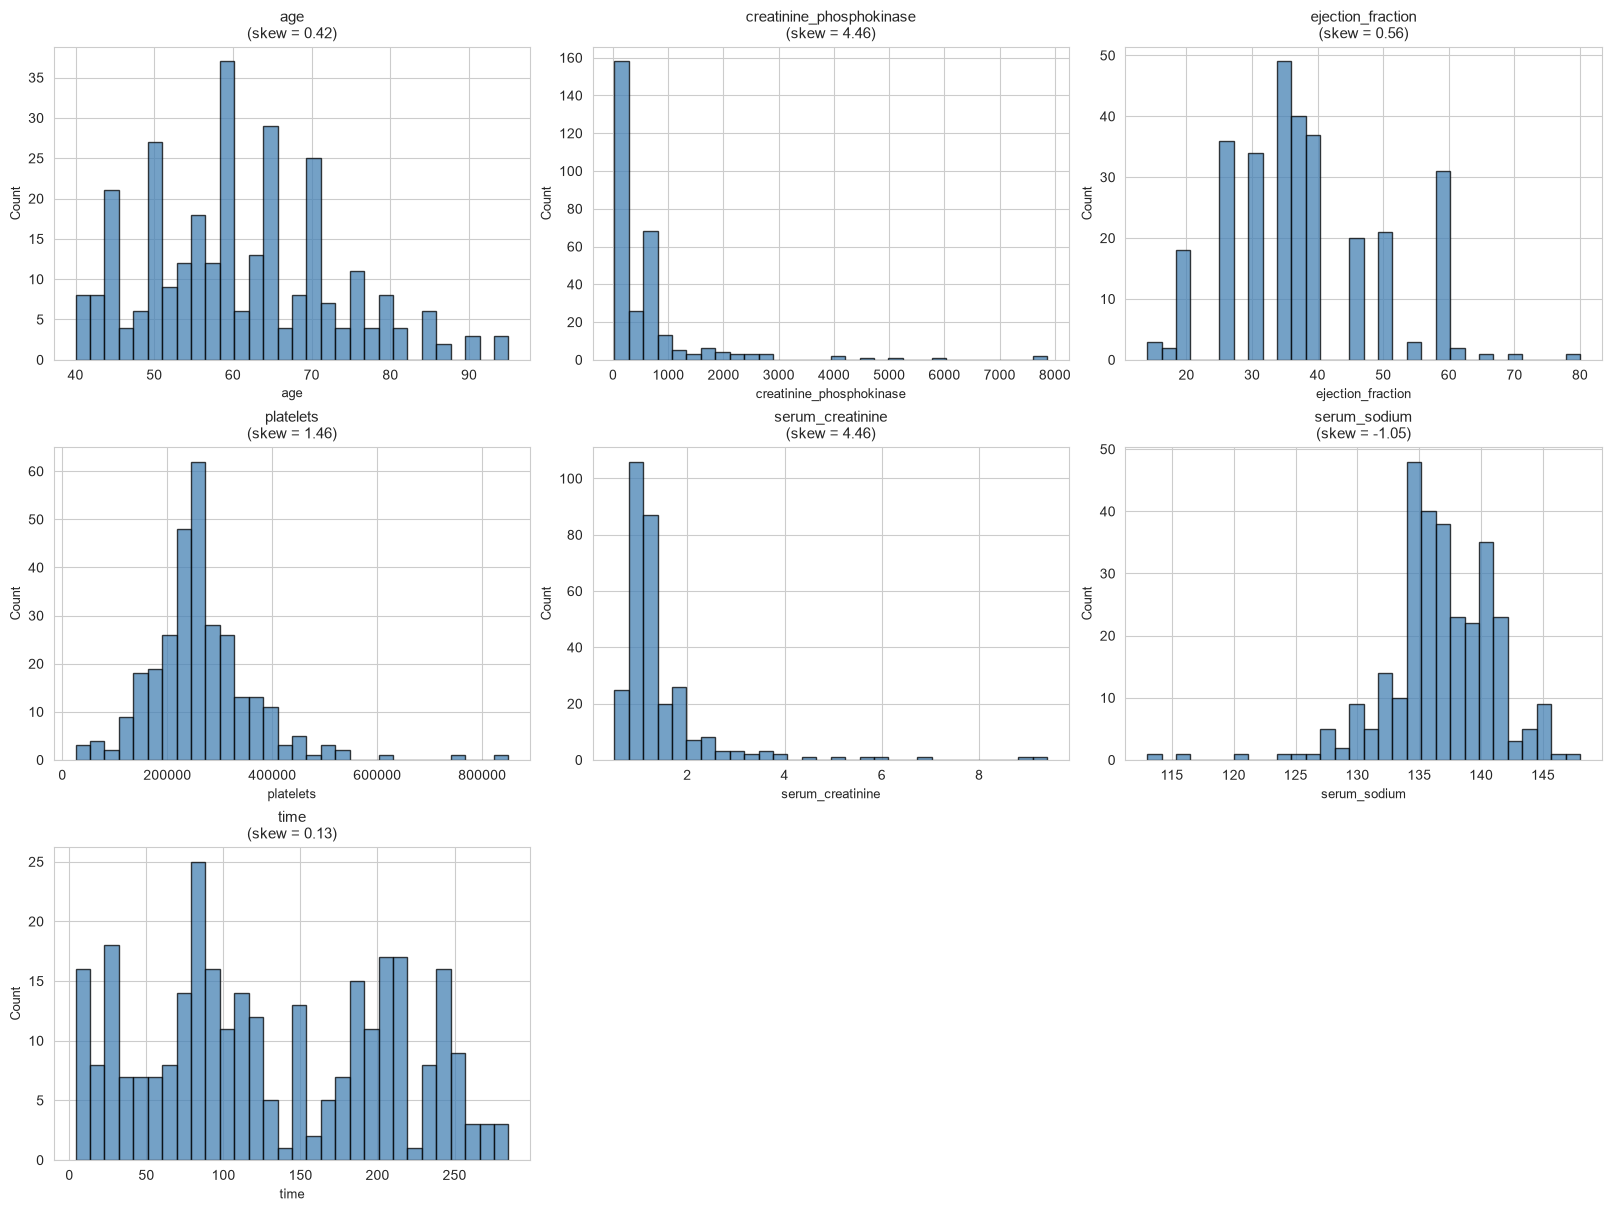

In [12]:
continuous_features =  ['age', 'creatinine_phosphokinase', 'ejection_fraction', 'platelets', 'serum_creatinine', 'serum_sodium', 'time']

fig, axes = plt.subplots(3, 3, figsize=(16, 12), constrained_layout=True)
axes = axes.flatten()

for i, feat in enumerate(continuous_features):
    axes[i].hist(df[feat], bins=30, color='steelblue',
                 edgecolor='black', alpha=0.75)
    axes[i].set_title(f'{feat}\n(skew = {df[feat].skew():.2f})', fontsize=11)
    axes[i].set_xlabel(feat, fontsize=9)
    axes[i].set_ylabel('Count', fontsize=9)

# Hide unused axes
for j in range(len(continuous_features), len(axes)):
    axes[j].axis('off')

plt.show()

Inferences: 
- creatinine_phosphokinase, serum_creatinine, platelets are heavily right-skewed (skew > 1) → consider log transform
- age, ejection_fraction, serum_sodium, time are roughly symmetric
- time is bimodal — possibly captures follow-up period

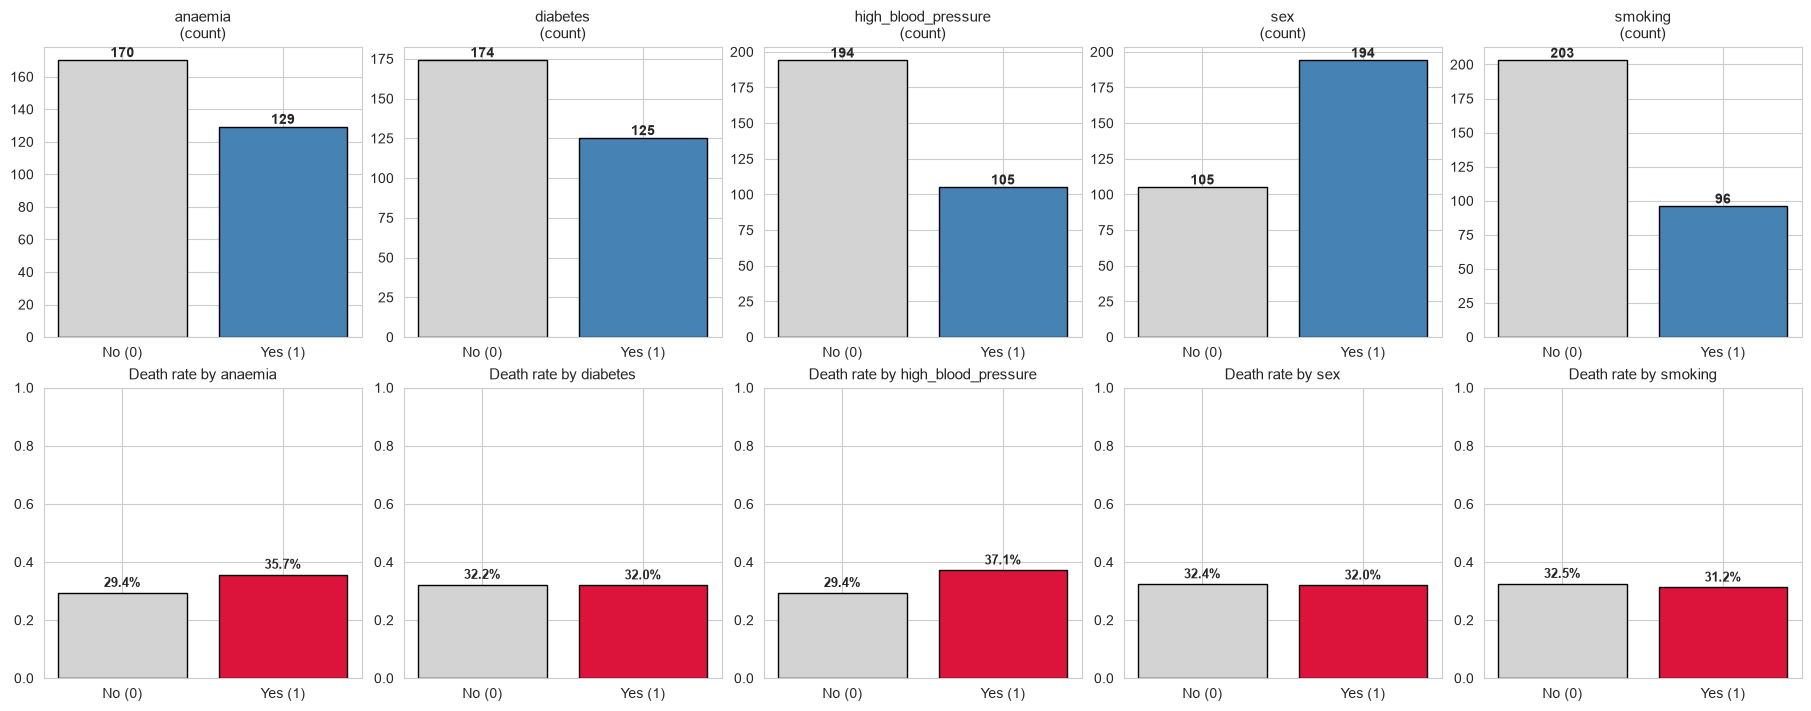

In [13]:
binary_features = ['anaemia', 'diabetes', 'high_blood_pressure', 'sex', 'smoking']
binary_counts = df[binary_features].sum()
fig, axes = plt.subplots(2, 5, figsize=(18, 7), constrained_layout=True)
axes = axes.flatten()

# Row 1: counts of binary features
for i, feat in enumerate(binary_features):
    counts = df[feat].value_counts().sort_index()
    axes[i].bar(['No (0)', 'Yes (1)'], counts.values,
                color=['lightgray', 'steelblue'], edgecolor='black')
    axes[i].set_title(f'{feat}\n(count)', fontsize=11)
    for x, v in enumerate(counts.values):
        axes[i].text(x, v + 2, str(v), ha='center', fontweight='bold')

# Row 2: death rate by binary feature
for i, feat in enumerate(binary_features):
    rate = df.groupby(feat)['DEATH_EVENT'].mean()
    bars = axes[5 + i].bar(['No (0)', 'Yes (1)'], rate.values,
                           color=['lightgray', 'crimson'], edgecolor='black')
    axes[5 + i].set_title(f'Death rate by {feat}', fontsize=11)
    axes[5 + i].set_ylim(0, 1)
    for bar, v in zip(bars, rate.values):
        axes[5 + i].text(bar.get_x() + bar.get_width()/2, v + 0.02,
                         f'{v:.1%}', ha='center', fontweight='bold', fontsize=9)

plt.show()

Inference: Binary features are reasonably balanced; smoking (32%) and high_blood_pressure (35%) are minority classes. This cell has a bug — it references axes[7] which is defined in a later cell.

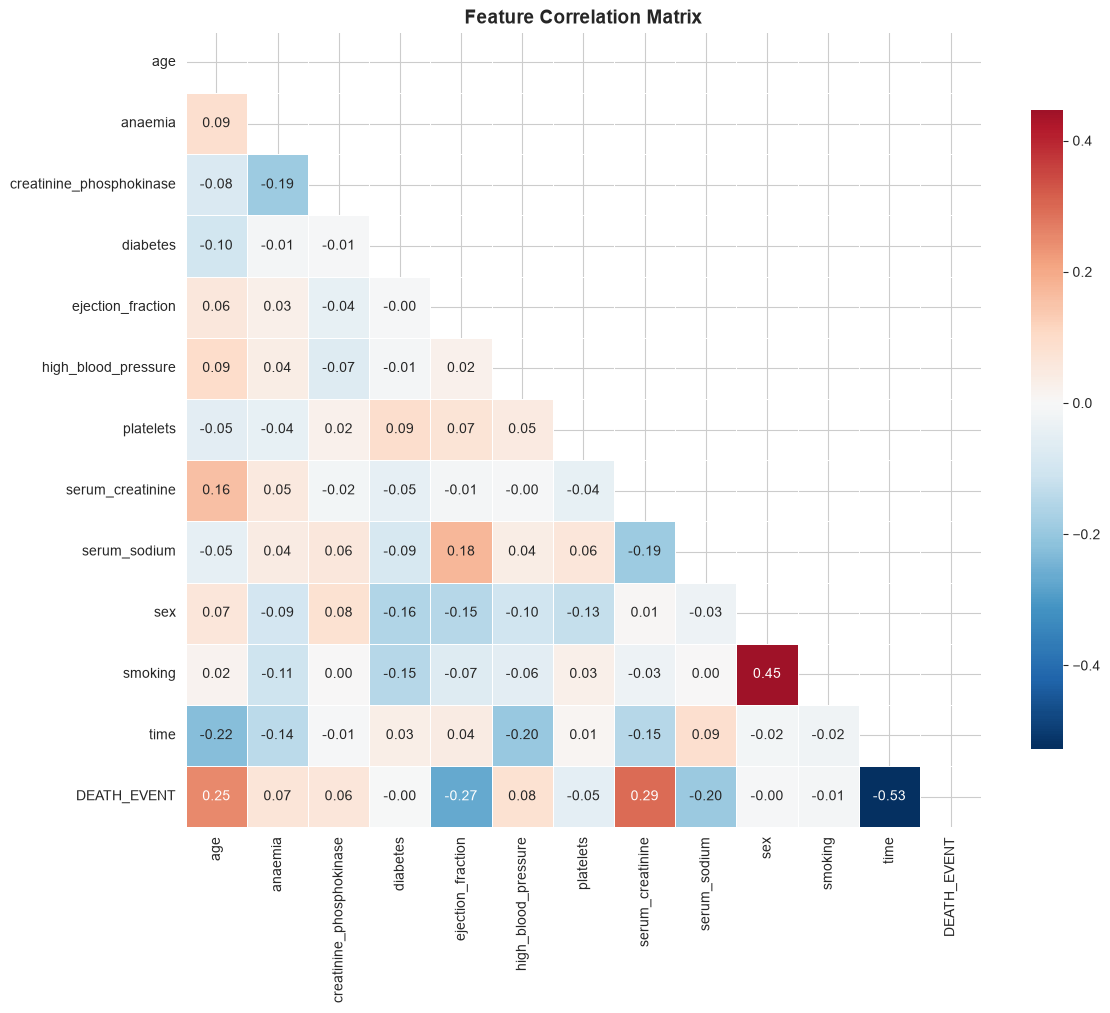

In [14]:
# Correlation Heatmap

plt.figure(figsize=(12, 10))
corr = df.corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
sns.heatmap(corr, mask=mask, annot=True, fmt='.2f', cmap='RdBu_r',
            center=0, square=True, linewidths=0.5, cbar_kws={'shrink': 0.8})
plt.title('Feature Correlation Matrix', fontsize=14, fontweight='bold')
plt.tight_layout()
# plt.savefig('../results/plots/03_correlation_heatmap.png', dpi=100, bbox_inches='tight')
plt.show()

In [15]:
# Top correlations with target
print("Top correlations with DEATH_EVENT:")
print(corr['DEATH_EVENT'].sort_values(ascending=False))

Top correlations with DEATH_EVENT:
DEATH_EVENT                 1.000000
serum_creatinine            0.294278
age                         0.253729
high_blood_pressure         0.079351
anaemia                     0.066270
creatinine_phosphokinase    0.062728
diabetes                   -0.001943
sex                        -0.004316
smoking                    -0.012623
platelets                  -0.049139
serum_sodium               -0.195204
ejection_fraction          -0.268603
time                       -0.526964
Name: DEATH_EVENT, dtype: float64


Inference:
- Strongest predictors of `DEATH_EVENT`:
- time (-0.53) — strongest, but likely a leakage risk (follow-up time)
- ejection_fraction (-0.27), serum_sodium (-0.20), serum_creatinine (+0.29), age (+0.25)
- diabetes, sex, smoking have near-zero correlation → weak standalone predictors
- No severe multicollinearity among features (all |r| < 0.35)

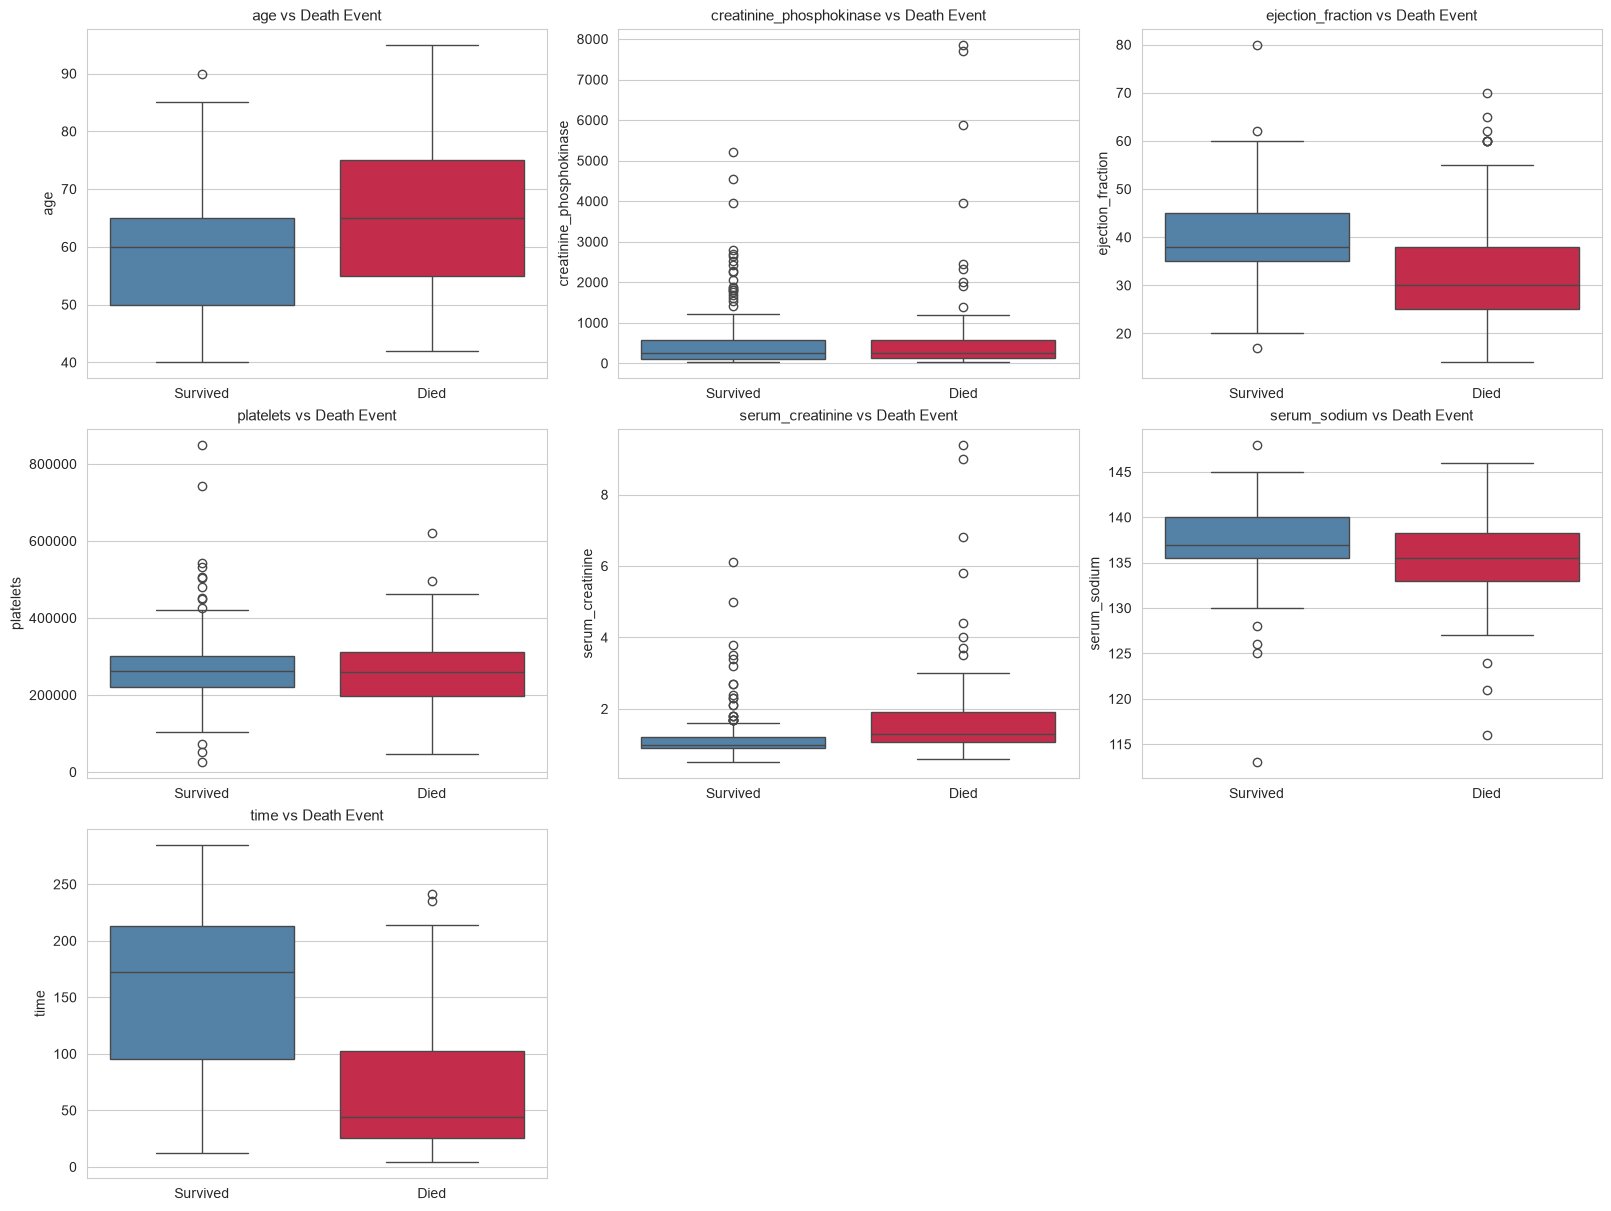

In [16]:
# Box Plots: features vs target 
fig, axes = plt.subplots(3, 3, figsize=(16, 12), constrained_layout=True)
axes = axes.flatten()

for i, feat in enumerate(continuous_features):
    sns.boxplot(data=df, x='DEATH_EVENT', y=feat, ax=axes[i],
                hue='DEATH_EVENT', palette=['steelblue', 'crimson'],
                legend=False)
    axes[i].set_title(f'{feat} vs Death Event', fontsize=11)
    axes[i].set_xticks([0, 1])
    axes[i].set_xticklabels(['Survived', 'Died'])
    axes[i].set_xlabel('')

for j in range(len(continuous_features), len(axes)):
    axes[j].axis('off')

plt.show()


Inference:

- Died patients have higher serum_creatinine and lower ejection_fraction — strong clinical signals
- time shows the clearest separation (died patients have much lower follow-up time)
- platelets, creatinine_phosphokinase show heavy outliers — robust scaling needed

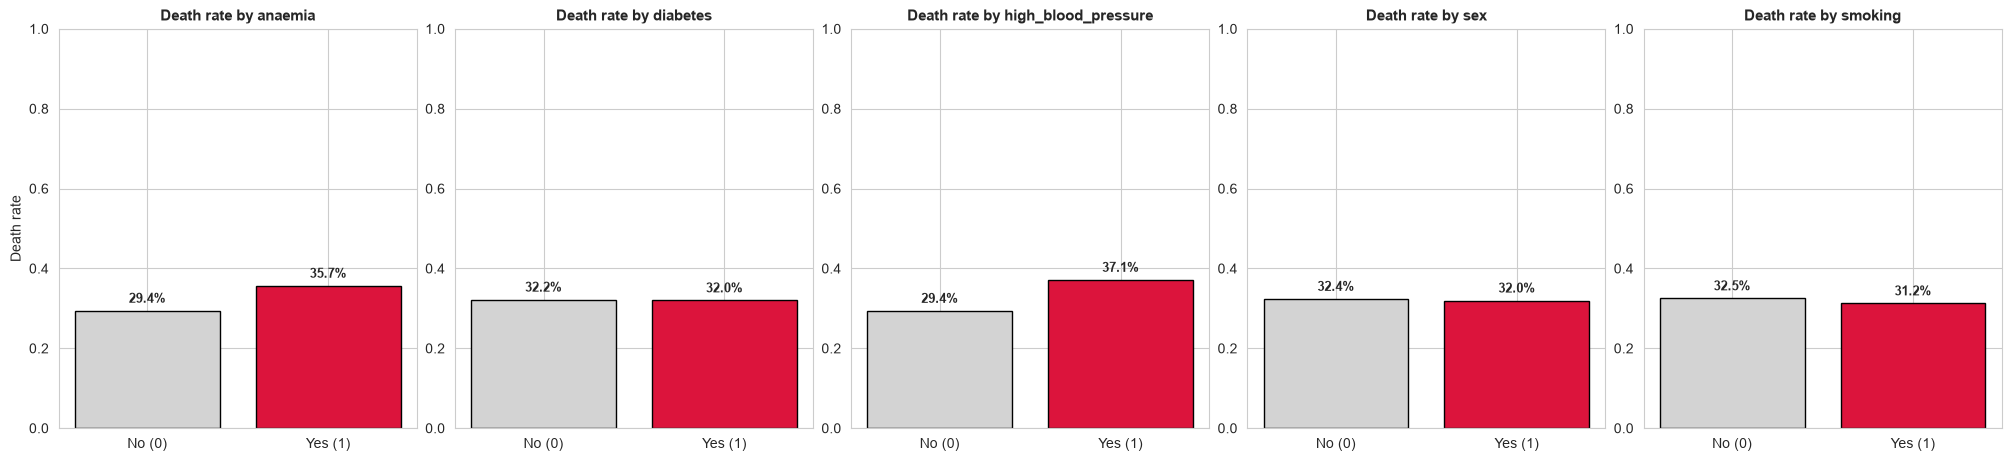

In [17]:
# Binary Features 
fig, axes = plt.subplots(1, 5, figsize=(20, 4.5), constrained_layout=True)

for i, feat in enumerate(binary_features):
    rate = df.groupby(feat)['DEATH_EVENT'].mean()
    bars = axes[i].bar(['No (0)', 'Yes (1)'], rate.values,
                       color=['lightgray', 'crimson'], edgecolor='black')
    axes[i].set_title(f'Death rate by {feat}', fontsize=11, fontweight='bold')
    axes[i].set_ylim(0, 1)
    axes[i].set_ylabel('Death rate' if i == 0 else '')
    for bar, v in zip(bars, rate.values):
        axes[i].text(bar.get_x() + bar.get_width()/2, v + 0.02,
                     f'{v:.1%}', ha='center', fontweight='bold', fontsize=9)

plt.show()

Inference: anaemia and diabetes show slightly higher death rates when present, but effect is weak.

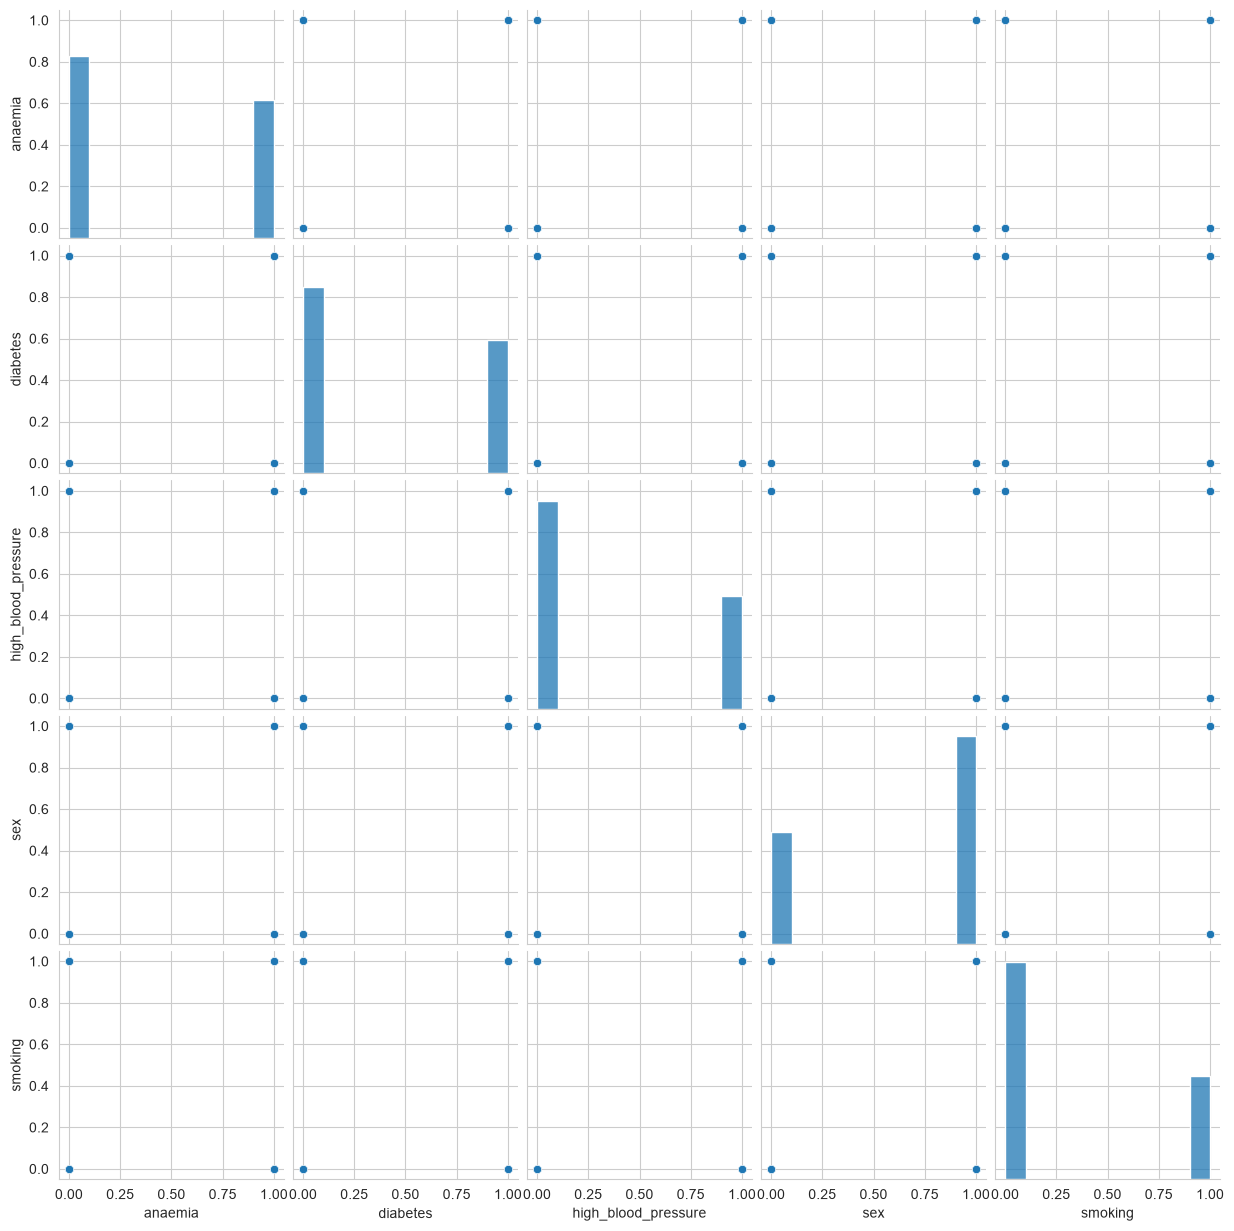

In [21]:
sns.pairplot(df[binary_features])